# Prompt Evaluation

In [12]:
evaluation_cases = [
    {
        "case_id": "eval_001",
        "requirement": "Design a secure serverless REST API on GCP.",
        "expected": ["Cloud Run", "IAM", "Cloud Logging"]
    },
    {
        "case_id": "eval_002",
        "requirement": "Design a Kubernetes platform on GCP.",
        "expected": ["GKE", "IAM", "Cloud Monitoring"]
    },
    {
        "case_id": "eval_003",
        "requirement": "Design a private PostgreSQL database on GCP.",
        "expected": ["Cloud SQL", "Private IP", "IAM"]
    }
]

for case in evaluation_cases:
    print(case["case_id"], "→", case["expected"])

eval_001 → ['Cloud Run', 'IAM', 'Cloud Logging']
eval_002 → ['GKE', 'IAM', 'Cloud Monitoring']
eval_003 → ['Cloud SQL', 'Private IP', 'IAM']


### 2. Define Candidate Prompts

We will compare two prompt strategies for generating GCP cloud architectures.

- **Prompt A (Basic):** A simple instruction without specific architecture guidelines.
- **Prompt B (Structured):** A detailed instruction covering security, monitoring, and cost optimization.

**Goal:** Evaluate whether a structured prompt produces more complete and reliable cloud architecture recommendations.

In [13]:
prompt_a = """
You are a cloud architect.

Design a GCP architecture for the following requirement:

{requirement}
"""

prompt_b = """
You are a senior GCP solution architect.

Design a secure, production-ready GCP architecture
for the following requirement:

{requirement}

Your response must include:
1. Recommended GCP services
2. Architecture overview
3. Security and IAM
4. Networking
5. Monitoring and logging
6. Cost optimization
"""

print("Prompt A:")
print(prompt_a.format(requirement=evaluation_cases[0]["requirement"]))

print("\nPrompt B:")
print(prompt_b.format(requirement=evaluation_cases[0]["requirement"]))

Prompt A:

You are a cloud architect.

Design a GCP architecture for the following requirement:

Design a secure serverless REST API on GCP.


Prompt B:

You are a senior GCP solution architect.

Design a secure, production-ready GCP architecture
for the following requirement:

Design a secure serverless REST API on GCP.

Your response must include:
1. Recommended GCP services
2. Architecture overview
3. Security and IAM
4. Networking
5. Monitoring and logging
6. Cost optimization



### 3. Execute Candidate Prompts

We simulate responses from two different prompt strategies using the same GCP architecture requirement.

- **Prompt A:** Generates a basic architecture recommendation.
- **Prompt B:** Generates a more detailed recommendation covering additional operational requirements.

**Goal:** Prepare comparable outputs for automated evaluation without making API calls.

**Note:** These are manually defined example responses, not actual LLM predictions. Real model evaluation will require running both prompts against the same test cases.

In [14]:
simulated_responses = {
    "prompt_a": """
    Deploy the REST API using Cloud Run.
    Use IAM for access control.
    """,
    "prompt_b": """
    Deploy the REST API using Cloud Run.

    Security:
    Use IAM with least-privilege permissions.

    Networking:
    Configure secure ingress and HTTPS.

    Monitoring:
    Use Cloud Logging and Cloud Monitoring.

    Cost:
    Configure Cloud Run scaling limits.
    """
}

for prompt_name, response in simulated_responses.items():
    print(f"\n--- {prompt_name.upper()} ---")
    print(response.strip())


--- PROMPT_A ---
Deploy the REST API using Cloud Run.
    Use IAM for access control.

--- PROMPT_B ---
Deploy the REST API using Cloud Run.

    Security:
    Use IAM with least-privilege permissions.

    Networking:
    Configure secure ingress and HTTPS.

    Monitoring:
    Use Cloud Logging and Cloud Monitoring.

    Cost:
    Configure Cloud Run scaling limits.


### 4. Automated Scoring

We evaluate the generated GCP architecture responses against predefined expected components.

**Evaluation metric: Component Coverage**

- Check whether each expected GCP component appears in the response.
- Count the number of matched components.
- Calculate a coverage score between 0.0 and 1.0.

**Formula:**

Coverage = Matched Components / Expected Components

**Goal:** Compare Prompt A and Prompt B using a consistent, reproducible evaluation metric.

**Limitation:** Keyword matching measures component coverage, not architectural correctness or implementation quality.

In [15]:
def evaluate_response(response: str, expected: list[str]) -> dict:
    response_lower = response.lower()

    matched = [
        component
        for component in expected
        if component.lower() in response_lower
    ]

    missing = [
        component
        for component in expected
        if component.lower() not in response_lower
    ]

    coverage = len(matched) / len(expected) if expected else 0.0

    return {
        "matched": matched,
        "missing": missing,
        "coverage": coverage,
    }


# Evaluate the first test case
expected = evaluation_cases[0]["expected"]

for prompt_name, response in simulated_responses.items():
    result = evaluate_response(response, expected)

    print(f"\n--- {prompt_name.upper()} ---")
    print("Matched:", result["matched"])
    print("Missing:", result["missing"])
    print(f"Coverage: {result['coverage']:.2%}")


--- PROMPT_A ---
Matched: ['Cloud Run', 'IAM']
Missing: ['Cloud Logging']
Coverage: 66.67%

--- PROMPT_B ---
Matched: ['Cloud Run', 'IAM', 'Cloud Logging']
Missing: []
Coverage: 100.00%


### 5. Failure Analysis

We analyze missing architecture components to understand why a prompt performs poorly.

**Objectives:**
- Identify missing GCP components.
- Classify incomplete architecture responses.
- Generate actionable feedback for prompt improvement.

**Goal:** Turn evaluation results into meaningful recommendations for improving prompt quality.

**Note:** This analysis uses component coverage, not a complete architectural quality assessment.

In [16]:
def analyze_failures(response: str, expected: list[str]) -> dict:
    evaluation = evaluate_response(response, expected)

    if not evaluation["missing"]:
        status = "PASS"
        feedback = "All expected components are present."
    else:
        status = "FAIL"
        feedback = (
            "Missing architecture components: "
            + ", ".join(evaluation["missing"])
        )

    return {
        "status": status,
        "coverage": evaluation["coverage"],
        "missing": evaluation["missing"],
        "feedback": feedback,
    }


expected = evaluation_cases[0]["expected"]

for prompt_name, response in simulated_responses.items():
    analysis = analyze_failures(response, expected)

    print(f"\n--- {prompt_name.upper()} ---")
    print("Status:", analysis["status"])
    print("Feedback:", analysis["feedback"])


--- PROMPT_A ---
Status: FAIL
Feedback: Missing architecture components: Cloud Logging

--- PROMPT_B ---
Status: PASS
Feedback: All expected components are present.


### 6. Prompt Improvement & Re-Evaluation

We use evaluation feedback to improve the original prompt.

**Objectives:**
- Identify missing architecture requirements.
- Create an improved Prompt C.
- Re-evaluate the response using the same evaluation criteria.
- Compare the results before and after improvement.

**Goal:** Demonstrate an iterative prompt engineering workflow:

Prompt → Evaluate → Analyze Failures → Improve → Re-Evaluate

In [17]:
prompt_c = """
You are a senior GCP solution architect.

Design a secure GCP architecture for:

{requirement}

Your architecture must include:
- Appropriate GCP compute services
- IAM and least-privilege access
- Cloud Logging
- Monitoring and operational visibility
- Cost optimization

Explain why each service is needed.
"""

# Simulated response for the improved prompt
simulated_response_c = """
Deploy the REST API using Cloud Run.

Use IAM with least-privilege permissions
to control access.

Enable Cloud Logging to collect application logs.

Use Cloud Monitoring for operational visibility.

Configure Cloud Run scaling limits
to manage infrastructure costs.
"""

expected = evaluation_cases[0]["expected"]

result_c = evaluate_response(
    simulated_response_c,
    expected
)

print("--- PROMPT C ---")
print("Matched:", result_c["matched"])
print("Missing:", result_c["missing"])
print(f"Coverage: {result_c['coverage']:.2%}")

--- PROMPT C ---
Matched: ['Cloud Run', 'IAM', 'Cloud Logging']
Missing: []
Coverage: 100.00%


### 7. Visualize Prompt Evaluation Results

We visualize the component coverage scores of three GCP architecture prompts.

- **Prompt A:** Basic architecture prompt
- **Prompt B:** Structured architecture prompt
- **Prompt C:** Improved prompt based on failure analysis

**Goal:** Compare evaluation results visually and identify improvements across prompt versions.

**Note:** Scores are based on simulated responses for a single evaluation case, not actual LLM predictions.

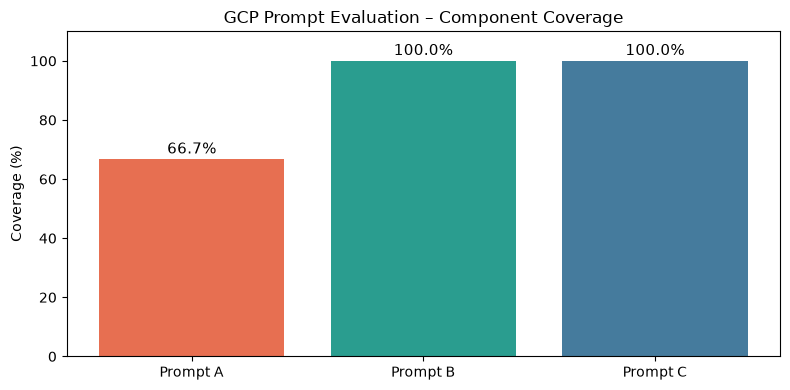

In [18]:
import matplotlib.pyplot as plt

# Evaluate all three simulated responses
responses = {
    "Prompt A": simulated_responses["prompt_a"],
    "Prompt B": simulated_responses["prompt_b"],
    "Prompt C": simulated_response_c,
}

expected = evaluation_cases[0]["expected"]

scores = {
    name: evaluate_response(response, expected)["coverage"] * 100
    for name, response in responses.items()
}

# Create comparison chart
fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    scores.keys(),
    scores.values(),
    color=["#E76F51", "#2A9D8F", "#457B9D"]
)

ax.set_title("GCP Prompt Evaluation – Component Coverage")
ax.set_ylabel("Coverage (%)")
ax.set_ylim(0, 110)

# Show percentages above bars
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.show()

### 8. Evaluate All Test Cases

We extend our prompt evaluation to multiple GCP architecture scenarios.

**Evaluation scenarios:**
- `eval_001`: Serverless REST API using Cloud Run
- `eval_002`: Kubernetes platform using GKE
- `eval_003`: Private PostgreSQL database using Cloud SQL

**Objectives:**
- Evaluate Prompt A, B, and C across all test cases.
- Calculate component coverage for each response.
- Compare average coverage across prompt variants.
- Identify missing architecture components.

**Note:** We continue using simulated responses to test our evaluation framework without API costs. These results do not represent actual LLM performance.

In [19]:
# Simulated responses for all evaluation cases

all_responses = {
    "Prompt A": {
        "eval_001": simulated_responses["prompt_a"],
        "eval_002": "Deploy the application using GKE.",
        "eval_003": "Use Cloud SQL for PostgreSQL.",
    },
    "Prompt B": {
        "eval_001": simulated_responses["prompt_b"],
        "eval_002": (
            "Deploy workloads on GKE. "
            "Use IAM for access control and "
            "Cloud Monitoring for observability."
        ),
        "eval_003": (
            "Use Cloud SQL with Private IP "
            "and IAM for secure database access."
        ),
    },
    "Prompt C": {
        "eval_001": simulated_response_c,
        "eval_002": (
            "Use GKE with IAM and Cloud Monitoring. "
            "Configure workload security and cost controls."
        ),
        "eval_003": (
            "Deploy PostgreSQL on Cloud SQL "
            "with Private IP connectivity and IAM."
        ),
    },
}

# Evaluate all responses
evaluation_results = []

for prompt_name, responses in all_responses.items():
    for case in evaluation_cases:
        case_id = case["case_id"]
        response = responses[case_id]

        result = evaluate_response(
            response,
            case["expected"]
        )

        evaluation_results.append({
            "prompt": prompt_name,
            "case_id": case_id,
            "coverage": result["coverage"],
            "missing": result["missing"],
        })

# Display results
for result in evaluation_results:
    print(
        f"{result['prompt']} | "
        f"{result['case_id']} | "
        f"Coverage: {result['coverage']:.1%} | "
        f"Missing: {result['missing']}"
    )

Prompt A | eval_001 | Coverage: 66.7% | Missing: ['Cloud Logging']
Prompt A | eval_002 | Coverage: 33.3% | Missing: ['IAM', 'Cloud Monitoring']
Prompt A | eval_003 | Coverage: 33.3% | Missing: ['Private IP', 'IAM']
Prompt B | eval_001 | Coverage: 100.0% | Missing: []
Prompt B | eval_002 | Coverage: 100.0% | Missing: []
Prompt B | eval_003 | Coverage: 100.0% | Missing: []
Prompt C | eval_001 | Coverage: 100.0% | Missing: []
Prompt C | eval_002 | Coverage: 100.0% | Missing: []
Prompt C | eval_003 | Coverage: 100.0% | Missing: []


### 9. Average Coverage and Visualization

We calculate the average component coverage for each prompt across all three GCP architecture evaluation cases.

**Objectives:**
- Aggregate evaluation results by prompt.
- Calculate average component coverage.
- Visualize and compare Prompt A, B, and C.
- Identify which prompt achieves the highest coverage.

**Metric:** Mean Component Coverage

**Limitation:** Results are based on manually simulated responses and keyword matching, not actual LLM performance or architectural correctness.

Prompt A: 44.44%
Prompt B: 100.00%
Prompt C: 100.00%


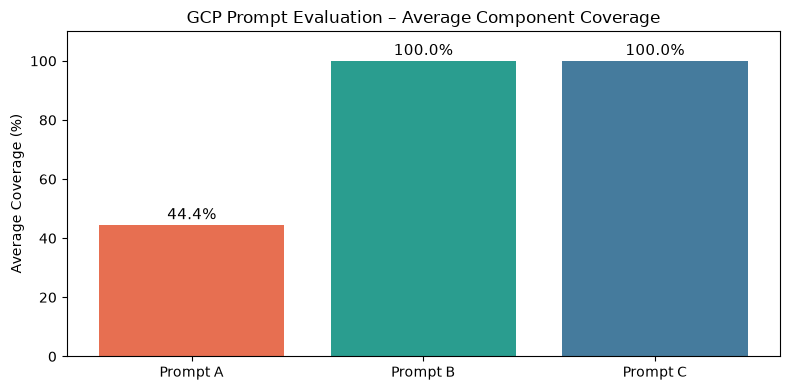

In [20]:
import matplotlib.pyplot as plt

# Calculate average coverage per prompt
average_scores = {}

for prompt_name in ["Prompt A", "Prompt B", "Prompt C"]:
    scores = [
        result["coverage"]
        for result in evaluation_results
        if result["prompt"] == prompt_name
    ]

    average_scores[prompt_name] = sum(scores) / len(scores) * 100

# Print results
for prompt_name, score in average_scores.items():
    print(f"{prompt_name}: {score:.2f}%")

# Visualize results
fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    average_scores.keys(),
    average_scores.values(),
    color=["#E76F51", "#2A9D8F", "#457B9D"]
)

ax.set_title("GCP Prompt Evaluation – Average Component Coverage")
ax.set_ylabel("Average Coverage (%)")
ax.set_ylim(0, 110)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.show()

### 10. Limitations & Lessons Learned

#### Limitations

Our GCP prompt evaluation framework demonstrates a basic evaluation workflow, but it has several limitations:

1. **Simulated LLM Responses:** All responses were manually defined. No actual LLM API calls were performed.
2. **Keyword-Based Evaluation:** Component coverage checks whether expected GCP services are mentioned, but does not verify their correct configuration.
3. **Small Evaluation Dataset:** Only three GCP architecture scenarios were evaluated: Cloud Run, GKE, and Cloud SQL.
4. **Limited Quality Metrics:** Security, networking, scalability, architecture correctness, and cost optimization were not independently evaluated.
5. **No Model Variability:** Real LLM outputs may vary between runs, even when using the same prompt.

#### Lessons Learned

- **Structured prompts improve guidance:** Explicit architecture requirements help guide models toward more complete responses.
- **Evaluation makes quality measurable:** Component coverage provides a simple, reproducible metric.
- **Failure analysis supports improvement:** Missing architecture components can be identified and used to refine prompts.
- **Prompt iteration is essential:** The workflow of Prompt → Evaluate → Improve → Re-Evaluate supports systematic prompt engineering.
- **High scores do not guarantee correctness:** A response mentioning Cloud SQL, IAM, and Private IP may still contain insecure or technically incorrect configurations.

#### Evaluation Results

| Prompt | Average Component Coverage |
|---|---|
| Prompt A – Basic | 44.4% |
| Prompt B – Structured | 100.0% |
| Prompt C – Improved | 100.0% |

*These results describe our simulated test cases and do not establish that Prompt B or C performs better on real LLM outputs.*

#### Next Steps

For a production-ready LLMOps evaluation pipeline:

- Replace simulated responses with actual LLM predictions.
- Expand the evaluation dataset with more realistic GCP architecture scenarios.
- Introduce security, architecture correctness, and cost evaluation metrics.
- Track prompt versions and evaluation results using MLflow or a similar experiment tracking system.
- Integrate automated prompt regression tests into CI/CD.

#### Conclusion

This notebook demonstrates the foundations of systematic prompt evaluation using GCP cloud architecture scenarios.

The key takeaway is:

**Prompt engineering is not just about writing better instructions. It is about measuring, understanding, and continuously improving the quality of model outputs.**